# CS6120 - Natural Language Processing 
## Instructor: Amir Tahmasebi
### Part I

# Introduction to Word Representations

Word representations are a fundamental concept in Natural Language Processing (NLP) that allow machines to understand words and texts by converting them into numerical form. 
The evolution from traditional to modern representation techniques has significantly improved the ability of models to understand semantics and context in language.



## One-Hot Vectors

One-hot encoding is a simple and popular method to represent words as vectors. 
Each word in the vocabulary is represented by a vector where one element is `1` and the rest are `0`.


In [1]:
# Code Example

import numpy as np

# Define a small vocabulary
vocabulary = ['cat', 'dog', 'mouse']

# Function to create one-hot vectors
def one_hot(word, vocab):
    # Initialize a vector of zeros
    vector = np.zeros(len(vocab))
    # Get the index of the word in the vocabulary and set that index to 1
    vector[vocab.index(word)] = 1
    return vector

# Example
word = 'cat'
vector = one_hot(word, vocabulary)
print(f"One-hot vector for '{word}': {vector}")

One-hot vector for 'cat': [1. 0. 0.]



## Bag of Words (BoW)

The Bag of Words model represents text as the multiset of its words, disregarding syntax and word order but keeping multiplicity.



In [3]:
### Code Example

from sklearn.feature_extraction.text import CountVectorizer

# Sample corpus
corpus = ['There is a nodule in the left lung.', 'There is a nodule in right breast.']

# Initialize the CountVectorizer
vectorizer = CountVectorizer()

# Fit and transform the corpus
X = vectorizer.fit_transform(corpus)

# Convert to array and show the result
print(vectorizer.get_feature_names_out())
print(X.toarray())


['breast' 'in' 'is' 'left' 'lung' 'nodule' 'right' 'the' 'there']
[[0 1 1 1 1 1 0 1 1]
 [1 1 1 0 0 1 1 0 1]]


## TF-IDF

Term Frequency-Inverse Document Frequency (TF-IDF) is a statistical measure used to evaluate the importance of a word to a document in a collection or corpus. The importance increases proportionally to the number of times a word appears in the document but is offset by the frequency of the word in the corpus. TF-IDF is widely used in information retrieval and text mining as a weighting factor in searches, document similarity measures, and model features for machine learning algorithms.

Components of TF-IDF:
Term Frequency (TF): This measures how frequently a term occurs in a document. Since every document is different in length, it is possible that a term would appear much more times in long documents than shorter ones. Thus, the term frequency is often divided by the document length (aka. the total number of terms in the document) as a way of normalization.

Inverse Document Frequency (IDF): This measures how important a term is. While computing TF, all terms are considered equally important. However, certain terms, such as "is", "of", and "that", may appear a lot of times but have little importance. 

Calculation of TF-IDF:
The TF-IDF value is calculated by multiplying TF and IDF scores of the term.

## Implementation from scratch

In [4]:
import pandas as pd
import math
from collections import Counter

# Sample corpus of clinical notes
corpus = [
    'Patient showed no adverse reactions to the new medication regimen.',
    'The new clinical trial for cancer treatment shows promising results.',
    'Adverse effects are minimal with the current treatment protocol.',
    'Clinical reviews for the latest medication have been overwhelmingly positive.',
    'The patient reports adverse symptoms following the medication change.'
]

# List of simple English stop words
stop_words = set(["the", "and", "is", "in", "to", "of"])

# Preprocessing: Tokenization, Lowercasing, and Stop Word Removal
def preprocess_document(doc):
    return [word.lower() for word in doc.split() if word.lower() not in stop_words]

preprocessed_corpus = [preprocess_document(doc) for doc in corpus]

# Compute TF
def compute_tf(document):
    tf_doc = Counter(document)
    len_doc = len(document)
    return {word: count / len_doc for word, count in tf_doc.items()}

# Compute IDF
def compute_idf(doc_list):
    N = len(doc_list)
    idf_dict = dict.fromkeys(set(word for doc in doc_list for word in doc), 0)
    for doc in doc_list:
        for word in set(doc):
            idf_dict[word] += 1
    return {word: math.log((N + 1) / (val + 1)) + 1 for word, val in idf_dict.items()}

tf_per_doc = [compute_tf(doc) for doc in preprocessed_corpus]
idfs = compute_idf(preprocessed_corpus)

# Compute TF-IDF and Apply L2 Normalization
def compute_tfidf_and_normalize(tf, idfs):
    tfidf = {word: (tf[word] * idfs[word]) for word in tf}
    norm = math.sqrt(sum(val**2 for val in tfidf.values()))
    return {word: val / norm for word, val in tfidf.items()}

tfidf_normalized = [compute_tfidf_and_normalize(doc, idfs) for doc in tf_per_doc]

# Creating DataFrame to store TF-IDF vectors
df_tfidf = pd.DataFrame(tfidf_normalized).fillna(0)

# Sorting DataFrame columns alphabetically
df_tfidf_sorted = df_tfidf.sort_index(axis=1)

# Printing the sorted DataFrame
print("TF-IDF Vectors stored in DataFrame, sorted alphabetically by words:")
df_tfidf_sorted.head()


TF-IDF Vectors stored in DataFrame, sorted alphabetically by words:


,adverse,are,been,cancer,change.,clinical,current,effects,following,for,...,regimen.,reports,results.,reviews,showed,shows,symptoms,treatment,trial,with
0,0.268987,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.401647,0.000000,0.000000,0.000000,0.401647,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.362651,0.000000,0.292584,0.000000,0.000000,0.000000,0.292584,...,0.000000,0.000000,0.362651,0.000000,0.000000,0.362651,0.000000,0.292584,0.362651,0.000000
2,0.251348,0.375308,0.000000,0.000000,0.000000,0.000000,0.375308,0.375308,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.302796,0.000000,0.375308
3,0.000000,0.000000,0.359203,0.000000,0.000000,0.289802,0.000000,0.000000,0.000000,0.289802,...,0.000000,0.000000,0.000000,0.359203,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.284329,0.000000,0.000000,0.000000,0.424555,0.000000,0.000000,0.000000,0.424555,0.000000,...,0.000000,0.424555,0.000000,0.000000,0.000000,0.000000,0.424555,0.000000,0.000000,0.000000


## TF-IDF
## using sklearn lib

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Sample corpus of clinical notes
corpus = [
    'Patient showed no adverse reactions to the new medication regimen.',
    'The new clinical trial for cancer treatment shows promising results.',
    'Adverse effects are minimal with the current treatment protocol.',
    'Clinical reviews for the latest medication have been overwhelmingly positive.',
    'The patient reports adverse symptoms following the medication change.'
]

# Initialize the TF-IDF Vectorizer with English stop words to exclude common words
vectorizer = TfidfVectorizer(stop_words='english')

# Fit and transform the corpus
tfidf_matrix = vectorizer.fit_transform(corpus)

# Get feature names to use as dataframe column headers
feature_names = vectorizer.get_feature_names_out()

# Display the TF-IDF matrix
import pandas as pd
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
df_tfidf.head()


,adverse,cancer,change,clinical,current,effects,following,latest,medication,minimal,...,reactions,regimen,reports,results,reviews,showed,shows,symptoms,treatment,trial
0,0.293720,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.293720,0.000000,...,0.438577,0.438577,0.000000,0.000000,0.000000,0.438577,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.379247,0.000000,0.305974,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.379247,0.000000,0.000000,0.379247,0.000000,0.305974,0.379247
2,0.296570,0.000000,0.000000,0.000000,0.442832,0.442832,0.000000,0.000000,0.000000,0.442832,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.357274,0.000000
3,0.000000,0.000000,0.000000,0.357274,0.000000,0.000000,0.000000,0.442832,0.296570,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.442832,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.284329,0.000000,0.424555,0.000000,0.000000,0.000000,0.424555,0.000000,0.284329,0.000000,...,0.000000,0.000000,0.424555,0.000000,0.000000,0.000000,0.000000,0.424555,0.000000,0.000000


## Co-Occurrence
Co-occurrence: number of times two words occur together in a context window


Co-occurrence Matrix:


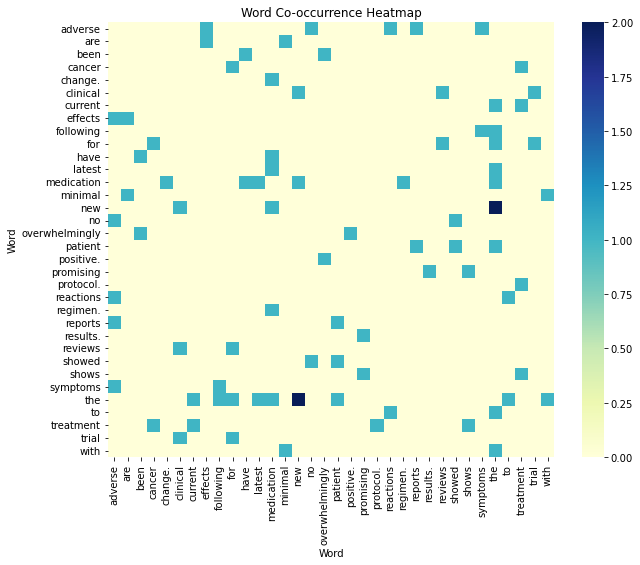

In [ ]:
from collections import Counter, defaultdict
import pandas as pd                          

# Sample corpus of clinical notes, preprocessed
corpus = [
    'Patient showed no adverse reactions to the new medication regimen.',
    'The new clinical trial for cancer treatment shows promising results.',
    'Adverse effects are minimal with the current treatment protocol.',
    'Clinical reviews for the latest medication have been overwhelmingly positive.',
    'The patient reports adverse symptoms following the medication change.'
]

# Preprocessing: Tokenization, Lowercasing
def preprocess_document(doc):
    return [word.lower() for word in doc.split()]

preprocessed_corpus = [preprocess_document(doc) for doc in corpus]

# Initialize an empty Counter object to hold our co-occurrences
co_occurrence = defaultdict(Counter)

# Define the context window size (we'll use a window of size 1 for simplicity)
window_size = 1

# Build the co-occurrence matrix
for doc in preprocessed_corpus:
    for i, word in enumerate(doc):
        start = max(i - window_size, 0)
        end = min(i + window_size + 1, len(doc))
        for j in range(start, end):
            if i != j:
                co_occurrence[word][doc[j]] += 1

# Convert the co-occurrence dictionary to a pandas DataFrame for easy viewing
co_occurrence_df = pd.DataFrame.from_dict(co_occurrence, orient='index').fillna(0)

# Sorting the DataFrame rows and columns alphabetically
co_occurrence_df = co_occurrence_df.sort_index().sort_index(axis=1)

print("Co-occurrence Matrix:")
co_occurrence_df.head()

import seaborn as sns
import matplotlib.pyplot as plt

# Assuming co_occurrence_df is the DataFrame created previously

# Visualize the co-occurrence matrix as a heatmap
plt.figure(figsize=(10, 8))  # Adjust the size as necessary
sns.heatmap(co_occurrence_df, annot=False, cmap='YlGnBu', cbar=True)

plt.title('Word Co-occurrence Heatmap')
plt.xlabel('Word')
plt.ylabel('Word')
plt.show()


## word2vec

In [7]:
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Sample clinical notes
clinical_notes = [
    'Patient showed no adverse reactions to the new medication regimen.',
    'The new clinical trial for cancer treatment shows promising results.',
    'Adverse effects are minimal with the current treatment protocol.',
    'Clinical reviews for the latest medication have been overwhelmingly positive.',
    'The patient reports adverse symptoms following the medication change.'
]

# Preprocess the text
processed_clinical_notes = [simple_preprocess(doc) for doc in clinical_notes]


In [8]:
# Train a Word2Vec model (Skip-gram)
model = Word2Vec(sentences=processed_clinical_notes, vector_size=100, window=5, sg=1, min_count=1)


In [9]:
# Find similar words
similar_words = model.wv.most_similar('medication', topn=5)
print("Words similar to 'medication':")
for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")


Words similar to 'medication':
are: 0.1898
cancer: 0.1891
been: 0.1605
protocol: 0.1590
overwhelmingly: 0.1378


In [25]:
# Example function to find and print similar words
def find_similar_words(word):
    try:
        similar_words = model.wv.most_similar(word, topn=5)
        print(f"Words similar to '{word}':")
        for word, similarity in similar_words:
            print(f"{word}: {similarity:.4f}")
    except KeyError:
        print(f"Word '{word}' not found in the vocabulary.")

# Interactive exploration (uncomment for interactive environments)
# query_word = input("Enter a word to find similar words: ")
# find_similar_words(query_word)


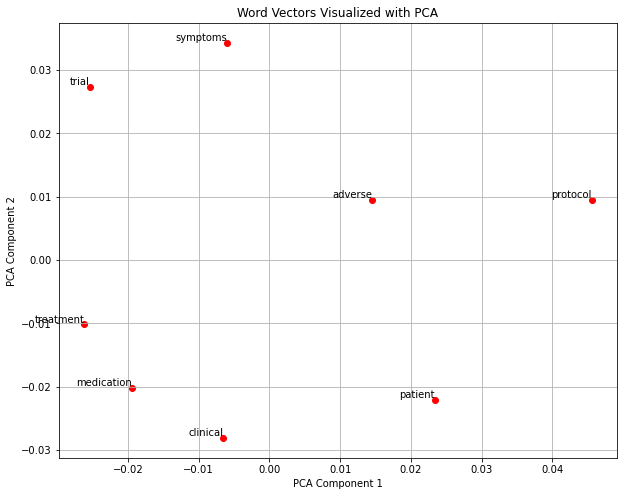

In [27]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Assuming 'model' is your trained Word2Vec model from the gensim library

# Extract the word vectors
word_vectors = model.wv

# Choose some words to visualize
words_of_interest = ['medication', 'treatment', 'clinical', 'patient', 'adverse', 'symptoms', 'trial', 'protocol']

# Get vectors for the selected words
vectors = [word_vectors[word] for word in words_of_interest]

# Perform PCA to reduce to 2D for visualization
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

# Plotting
plt.figure(figsize=(10, 8))
# Scatter plot for the vectors
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], color='red')

# Adjusting text placement here, reducing the offset to position text closer to the dots
for word, (x, y) in zip(words_of_interest, vectors_2d):
    plt.text(x, y, word, ha='right', va='bottom')

plt.title('Word Vectors Visualized with PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()


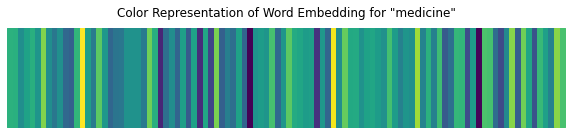

In [29]:
from gensim.models import KeyedVectors
from gensim.downloader import load

# Load a pre-trained Word2Vec model (this might take some time)
# For example, using the "glove-wiki-gigaword-100" model
model = load('glove-wiki-gigaword-100')


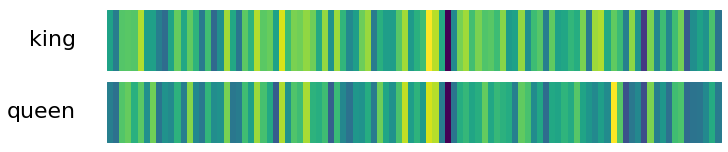

In [80]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib

matplotlib.rcParams.update({'font.size': 22})

# words = ['medicine', 'doctor', 'hospital', 'treatment', 'health']
words = ['king', 'queen']#, 'prince', 'princess', 'man', 'woman', 'check-out','check-in','father-in-law','mother-in-law']

# Prepare the plot
fig, axs = plt.subplots(len(words), 1, figsize=(10, len(words)), constrained_layout=True)
if len(words) == 1:  # If there's only one word, axs needs to be an array
    axs = [axs]

# Set a constant to control how far to the left the word labels will appear
label_offset = -5

for ax, word in zip(axs, words):
    if word in model:
        vector = model[word]
        # Normalize the vector
        normalized_vector = (vector - np.min(vector)) / (np.max(vector) - np.min(vector))
        # Map to colors
        cmap = plt.get_cmap('viridis')
        colors = cmap(normalized_vector)
        # Plot each dimension as a colored segment
        for i, color in enumerate(colors):
            ax.fill_between([i, i+1], 0, 1, color=color)
        ax.set_xlim(label_offset, len(vector))
        ax.axis('off')
        # Place the word label to the left of the vector
        ax.text(label_offset, 0.5, word, verticalalignment='center', horizontalalignment='right')
    else:
        ax.axis('off')
        # If the word is not in the vocabulary, indicate it
        ax.text(label_offset, 0.5, f'"{word}" - Not in vocabulary', verticalalignment='center', horizontalalignment='right', color='red')

    
plt.show()

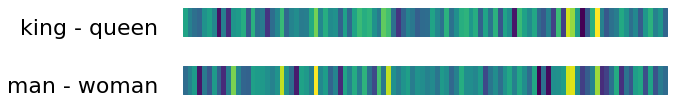

In [79]:
# from gensim.downloader import load
# import numpy as np
# import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams.update({'font.size': 26})

# # Load a pre-trained Word2Vec model
# model = load('glove-wiki-gigaword-100')  # Loading a GloVe model

# Define your word pairs
word_pairs = [('king', 'queen'), ('man', 'woman')]

# Check if words are in the model to avoid KeyError, using key_to_index for Gensim 4.0.0+
subtracted_embeddings = [(model[w1] - model[w2]) for w1, w2 in word_pairs if w1 in model.key_to_index and w2 in model.key_to_index]

# Visualization function
def visualize_embeddings(embeddings, labels):
    plt.figure(figsize=(10, len(embeddings)))
    for i, (embedding, label) in enumerate(zip(embeddings, labels)):
        # Normalize the embedding
        normalized_embedding = (embedding - np.min(embedding)) / (np.max(embedding) - np.min(embedding))
        cmap = plt.get_cmap('viridis')
        colors = cmap(normalized_embedding)
        
        # Plot each dimension as a colored segment
        plt.subplot(len(embeddings), 1, i + 1)
        for j, color in enumerate(colors):
            plt.fill_between([j, j+1], i, i+1, color=color)
        plt.xlim(0, len(embedding))
        plt.text(-5, i + 0.25, label, va='center', ha='right', fontsize=22)
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# Create labels for visualization
labels = [f'{w1} - {w2}' for w1, w2 in word_pairs if w1 in model.key_to_index and w2 in model.key_to_index]

# Visualize the subtracted embeddings
visualize_embeddings(subtracted_embeddings, labels)
